In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
url = "https://raw.githubusercontent.com/IBM/watson-studio-learning-path-assets/master/data/customer-churn-kaggle.csv"
df = pd.read_csv(url)
df.head()

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [2]:
df.shape

(3333, 21)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   str    
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   str    
 4   international plan      3333 non-null   str    
 5   voice mail plan         3333 non-null   str    
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   int64  
 15

In [4]:
df.describe()

,account length,area code,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,437.182418,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,42.371290,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,415.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [5]:
df.isnull().sum()
    

state                     0
account length            0
area code                 0
phone number              0
international plan        0
voice mail plan           0
number vmail messages     0
total day minutes         0
total day calls           0
total day charge          0
total eve minutes         0
total eve calls           0
total eve charge          0
total night minutes       0
total night calls         0
total night charge        0
total intl minutes        0
total intl calls          0
total intl charge         0
customer service calls    0
churn                     0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.columns.tolist()

['state',
 'account length',
 'area code',
 'phone number',
 'international plan',
 'voice mail plan',
 'number vmail messages',
 'total day minutes',
 'total day calls',
 'total day charge',
 'total eve minutes',
 'total eve calls',
 'total eve charge',
 'total night minutes',
 'total night calls',
 'total night charge',
 'total intl minutes',
 'total intl calls',
 'total intl charge',
 'customer service calls',
 'churn']

In [8]:
df['churn'].value_counts()

churn
False    2850
True      483
Name: count, dtype: int64

In [9]:
df['churn'].value_counts(normalize=True) * 100

churn
False    85.508551
True     14.491449
Name: proportion, dtype: float64

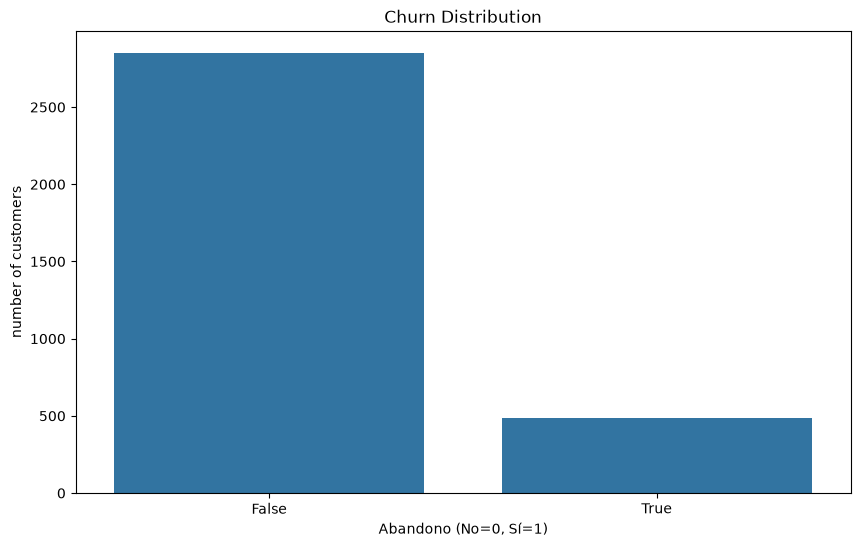

In [10]:
plt.figure(figsize=(10,6))
sns.countplot(x='churn', data=df)
plt.title('Churn Distribution')
plt.xlabel('Abandono (No=0, Sí=1)')
plt.ylabel('number of customers')
plt.show()

In [11]:
df.select_dtypes(include='object').nunique()

/tmp/ipykernel_4726/3404847108.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').nunique()


state                   51
phone number          3333
international plan       2
voice mail plan          2
dtype: int64

In [12]:
df.describe().loc[['mean', '50%', 'std']].round(2)

,account length,area code,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls
mean,101.06,437.18,8.10,179.78,100.44,30.56,200.98,100.11,17.08,200.87,100.11,9.04,10.24,4.48,2.76,1.56
50%,101.00,415.00,0.00,179.40,101.00,30.50,201.40,100.00,17.12,201.20,100.00,9.05,10.30,4.00,2.78,1.00
std,39.82,42.37,13.69,54.47,20.07,9.26,50.71,19.92,4.31,50.57,19.57,2.28,2.79,2.46,0.75,1.32


In [13]:
df.groupby('churn').mean(numeric_only=True).T.round(2)

churn,False,True
account length,100.79,102.66
area code,437.07,437.82
number vmail messages,8.60,5.12
total day minutes,175.18,206.91
total day calls,100.28,101.34
total day charge,29.78,35.18
total eve minutes,199.04,212.41
total eve calls,100.04,100.56
total eve charge,16.92,18.05
total night minutes,200.13,205.23


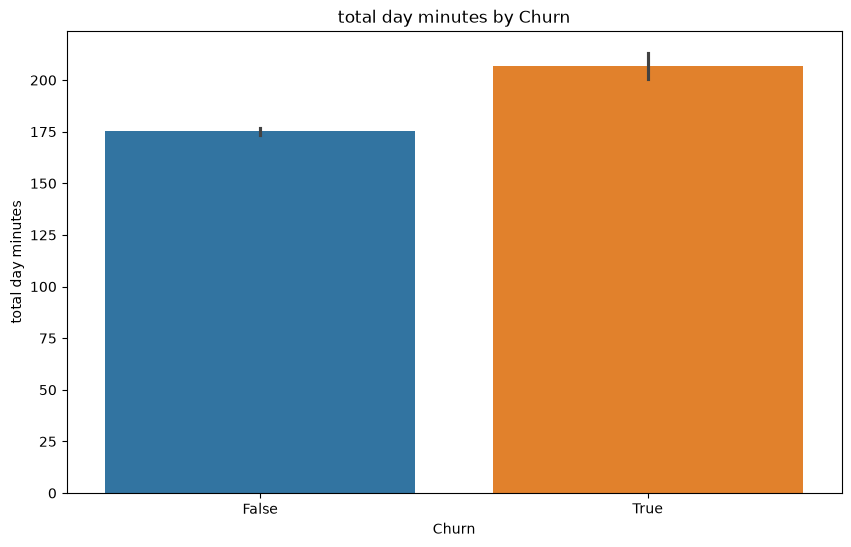

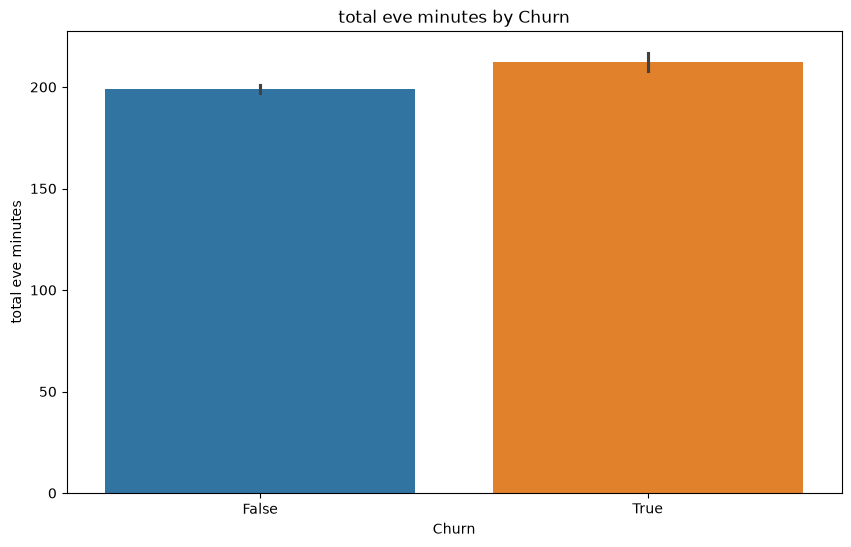

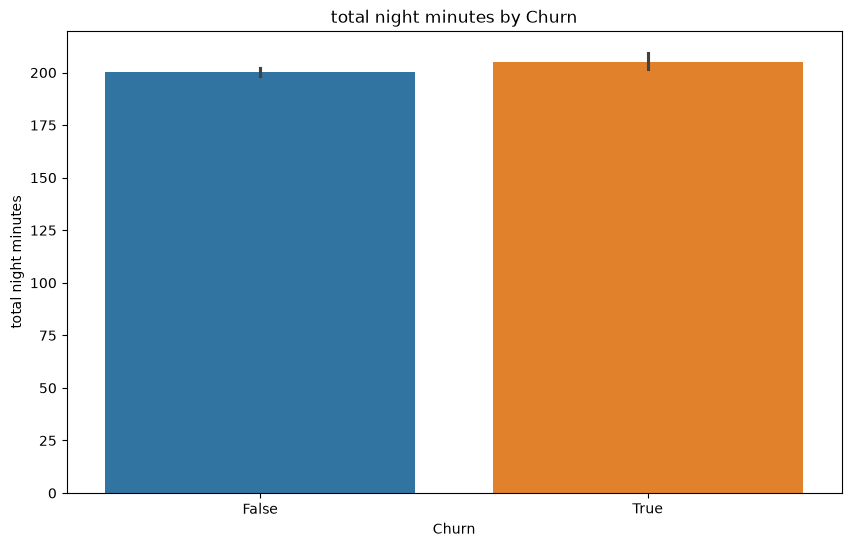

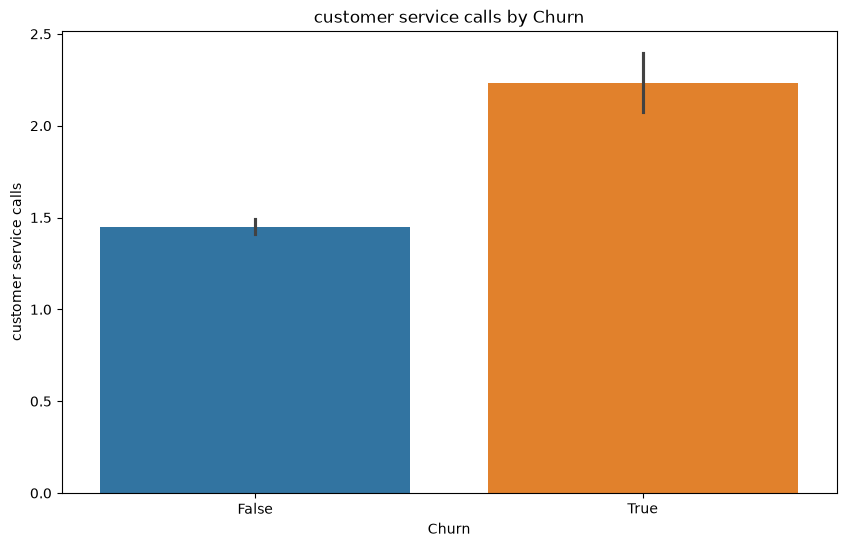

In [14]:
variables = ['total day minutes',
             'total eve minutes',
             'total night minutes',
             'customer service calls']
for var in variables:
    plt.figure(figsize=(10,6))
    sns.barplot(data= df, x='churn', y=var, hue='churn', legend=False)
    plt.title(f'{var} by Churn')
    plt.xlabel('Churn')
    plt.ylabel(var)
    plt.show()

In [15]:
for col in ['international plan', 'voice mail plan', 'area code']:
    print(f'Abandona segun {col}')
    resultado = pd.crosstab(df[col], df['churn'], normalize='index') * 100
    print(resultado.round(2))
    print()

Abandona segun international plan
churn               False  True 
international plan              
no                  88.50  11.50
yes                 57.59  42.41

Abandona segun voice mail plan
churn            False  True 
voice mail plan              
no               83.28  16.72
yes              91.32   8.68

Abandona segun area code
churn      False  True 
area code              
408        85.44  14.56
415        85.74  14.26
510        85.12  14.88



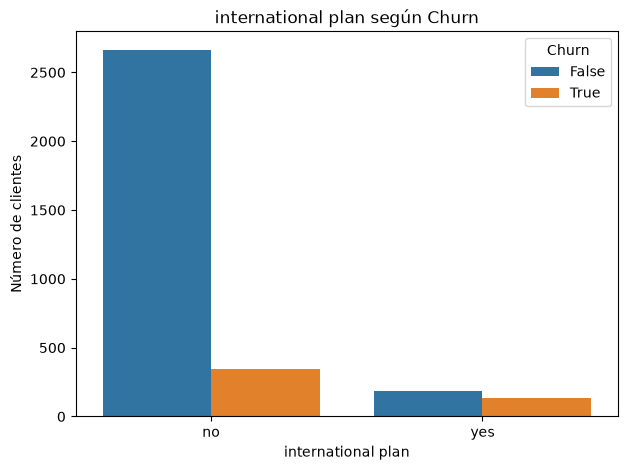

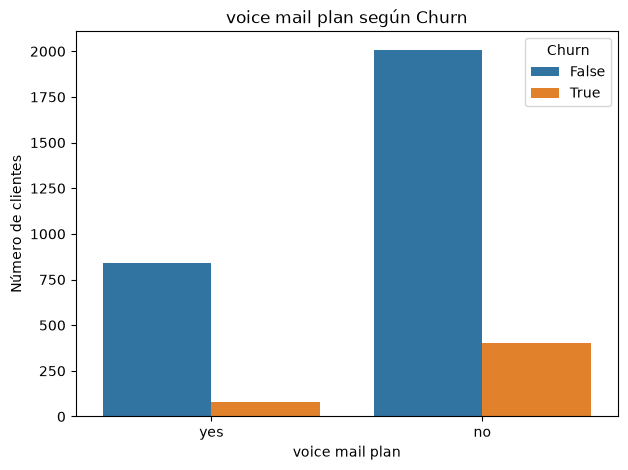

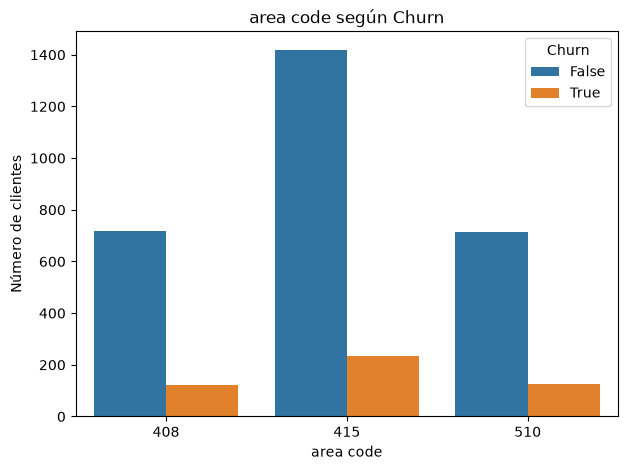

In [16]:
variables = [
    'international plan',
    'voice mail plan',
    'area code'
]

for col in variables:

    plt.figure(figsize=(7, 5))

    sns.countplot(
        data=df,
        x=col,
        hue='churn'
    )

    plt.title(f'{col} según Churn')
    plt.xlabel(col)
    plt.ylabel('Número de clientes')
    plt.legend(title='Churn')

    plt.show()

### 📊 Análisis de variables categóricas

Durante el análisis de las variables categóricas hemos encontrado diferencias importantes en el comportamiento de los clientes.

**1. International plan**

Los clientes que tienen contratado un plan internacional presentan una tasa de abandono del 42,41 %, frente al 11,50 % de los clientes que no lo tienen.

Esta variable muestra una asociación importante con el abandono.

**2. Voice mail plan**

Los clientes que tienen contratado el servicio de buzón de voz presentan una tasa de abandono del 8,68 %, mientras que los que no lo tienen alcanzan el 16,72 %.

Esto sugiere una posible relación entre este servicio y una mayor permanencia.

**3. Area code**

Los tres códigos de área presentan tasas de abandono muy similares, situadas aproximadamente entre el 14 % y el 15 %.

Por tanto, esta variable no parece mostrar diferencias relevantes en nuestro análisis inicial.

**Conclusión general:** `international plan` y `voice mail plan` son variables interesantes para nuestro futuro modelo de clasificación. No eliminaremos ninguna variable basándonos únicamente en este análisis exploratorio.

In [17]:
churn_state= (df.groupby('state')['churn']
              .agg(['count', 'mean'])
              .sort_values(by='mean', ascending=False))
churn_state['mean'] = churn_state['mean'] * 100
churn_state = churn_state.rename(columns={'count': 'Customer Count', 'mean': 'taza de abandono %'})
churn_state.round(2)

,Customer Count,taza de abandono %
state,,
CA,34,26.47
NJ,68,26.47
TX,72,25.00
MD,70,24.29
SC,60,23.33
MI,73,21.92
MS,65,21.54
WA,66,21.21
NV,66,21.21


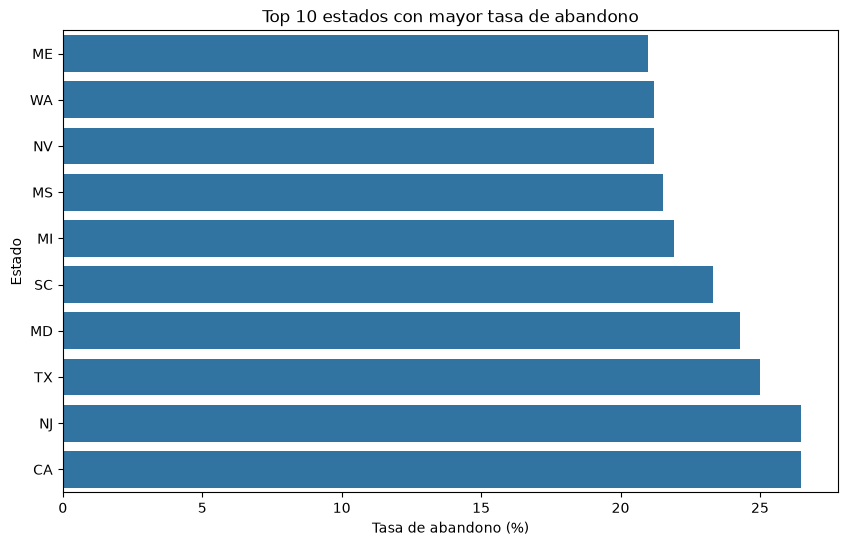

In [18]:
top_10 = churn_state.head(10).sort_values(
    'taza de abandono %',
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10.reset_index(),
    x='taza de abandono %',
    y='state'
)

plt.title('Top 10 estados con mayor tasa de abandono')
plt.xlabel('Tasa de abandono (%)')
plt.ylabel('Estado')

plt.show()

### 📍 Análisis geográfico del abandono de clientes

Durante el análisis de la variable `state` hemos encontrado diferencias importantes en las tasas de abandono entre los distintos estados.

Los estados con mayores tasas son California (CA) y New Jersey (NJ), ambos con un 26,47 %, seguidos de Texas (TX), con un 25 %.

Por otro lado, Hawaii (HI) presenta la menor tasa de abandono, con un 5,66 %.

Estos resultados sugieren que la ubicación geográfica podría estar relacionada con el comportamiento de abandono de los clientes.

Sin embargo, debemos tener en cuenta el número de observaciones de cada estado, ya que algunas tasas se calculan sobre muestras relativamente pequeñas.

**Conclusión:** conservaremos la variable `state` para estudiar su posible capacidad predictiva en los modelos de clasificación. No podemos determinar su importancia definitiva únicamente mediante este análisis descriptivo.

In [19]:
variables = [
    'account length',
    'number vmail messages',
    'total day minutes',
    'total day calls',
    'total day charge',
    'total eve minutes',
    'total eve calls',
    'total eve charge',
    'total night minutes',
    'total night calls',
    'total night charge',
    'total intl minutes',
    'total intl calls',
    'total intl charge',
    'customer service calls'
]

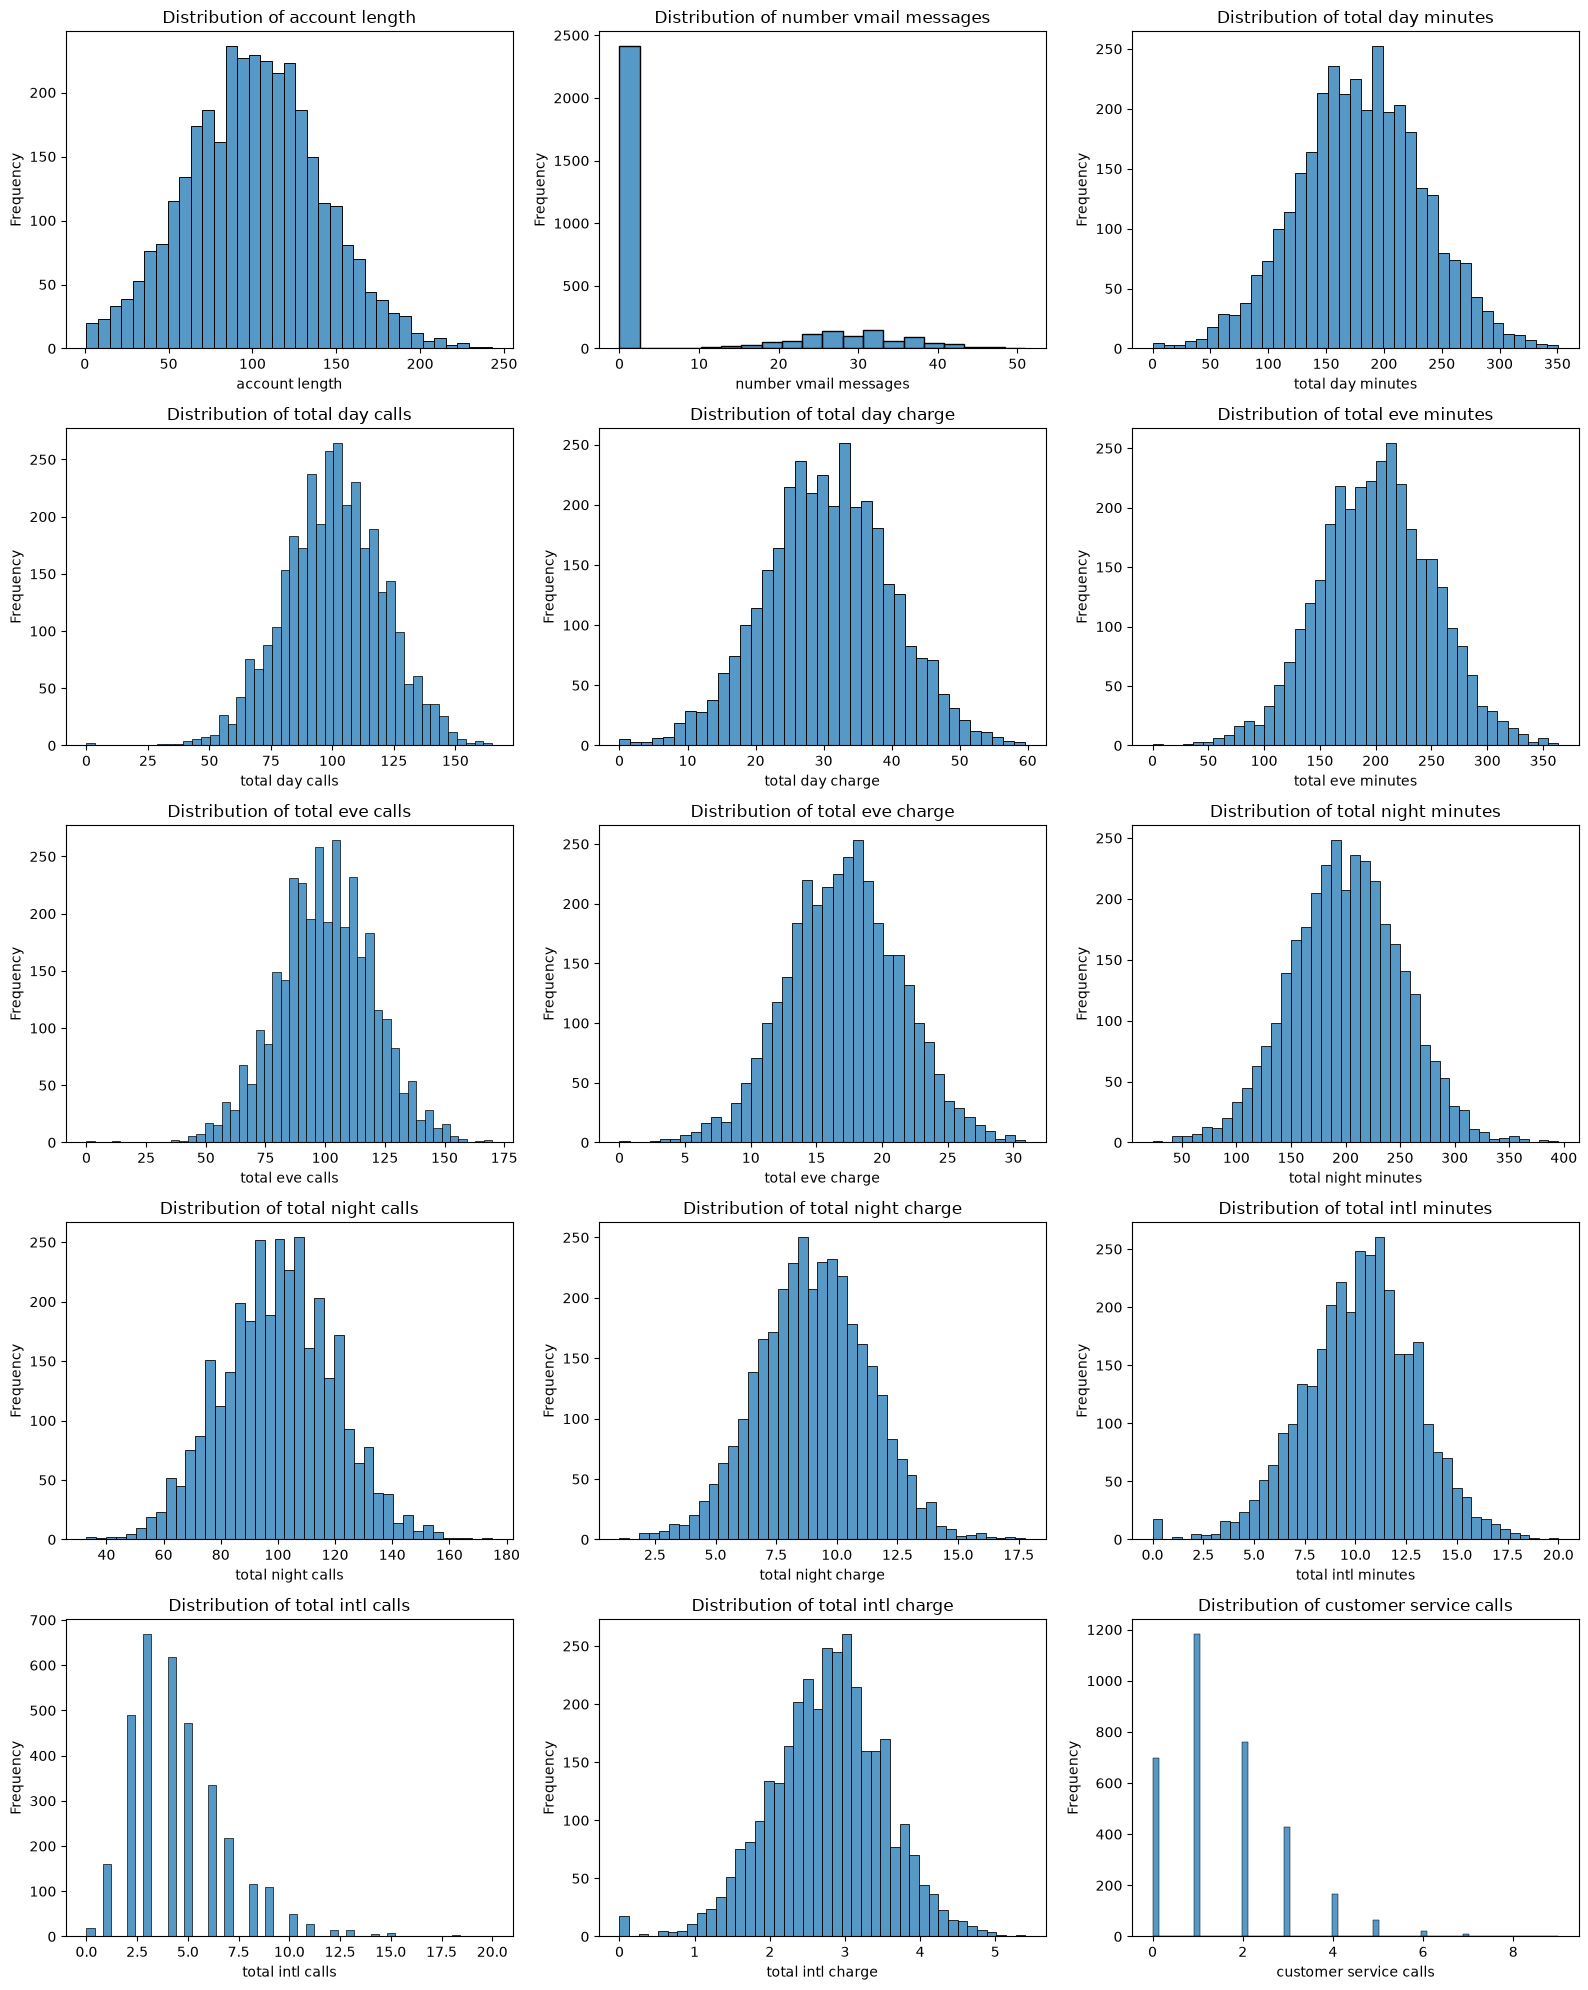

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 3
n_rows = math.ceil(len(variables) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(variables):
    sns.histplot(
        data=df,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
    
plt.tight_layout()
plt.show()

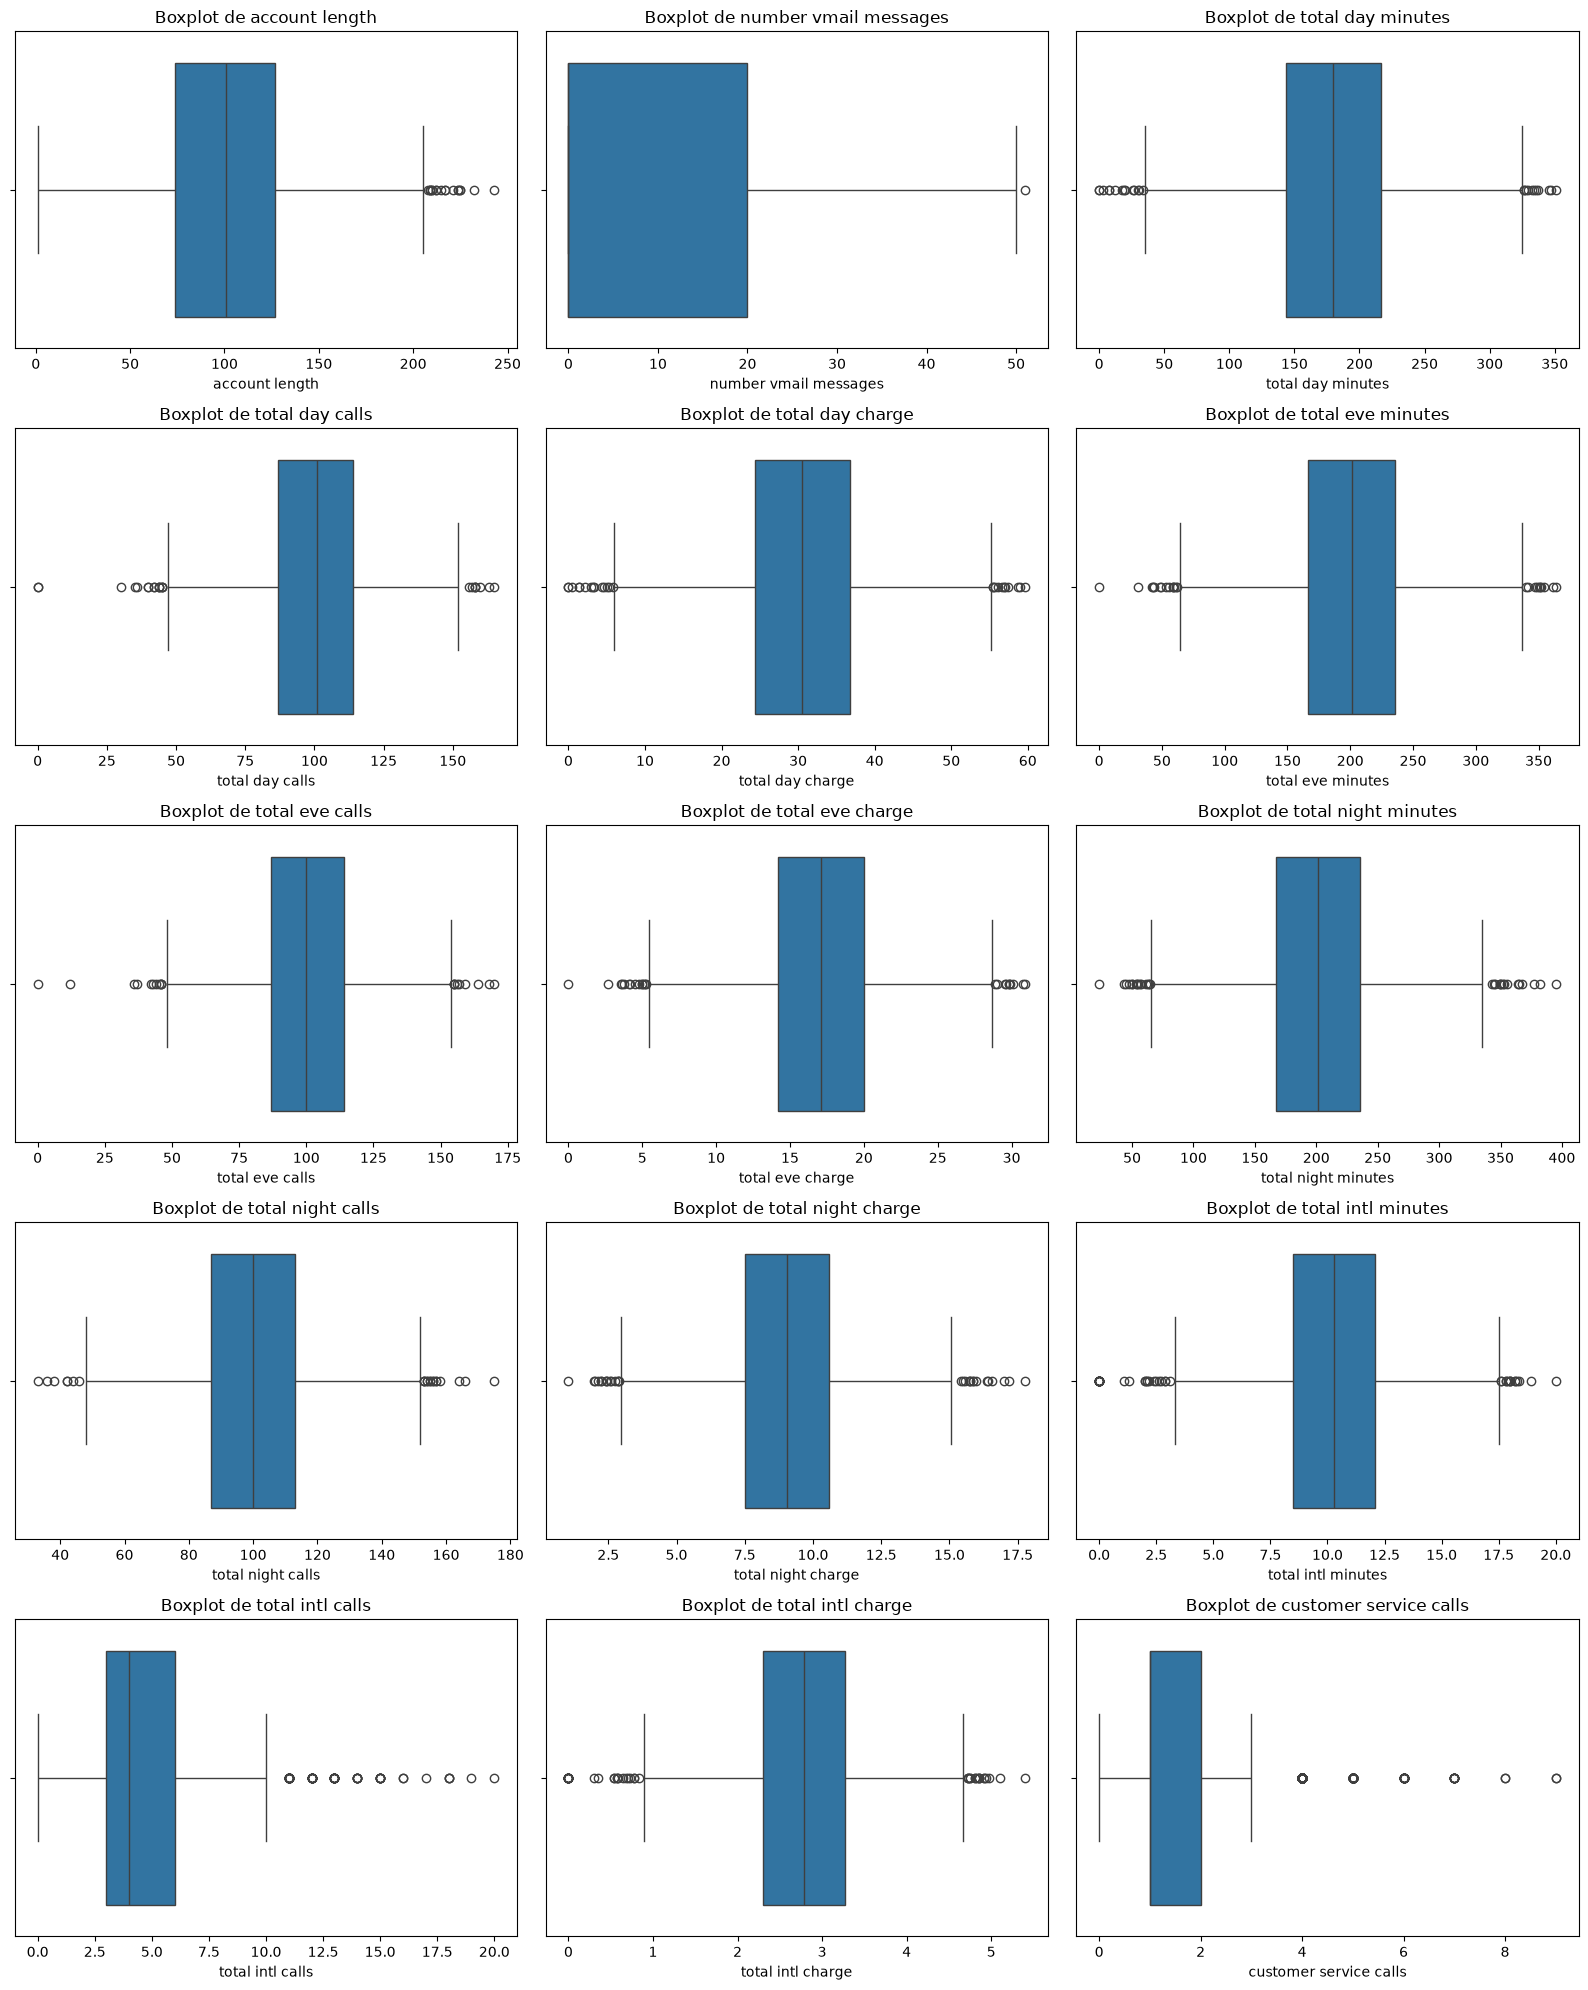

In [21]:
n_cols = 3
n_rows = math.ceil(len(variables) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(variables):

    sns.boxplot(
        data=df,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f'Boxplot de {col}')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [22]:
resultados = []

for col in variables:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < limite_inferior) |
        (df[col] > limite_superior)
    ]

    resultados.append({
        'Variable': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Limite inferior': limite_inferior,
        'Limite superior': limite_superior,
        'Numero outliers': len(outliers),
        'Porcentaje (%)': len(outliers) / len(df) * 100
    })

df_outliers = pd.DataFrame(resultados)

df_outliers.round(2)

,Variable,Q1,Q3,IQR,Limite inferior,Limite superior,Numero outliers,Porcentaje (%)
0,account length,74.00,127.00,53.00,-5.50,206.50,18,0.54
1,number vmail messages,0.00,20.00,20.00,-30.00,50.00,1,0.03
2,total day minutes,143.70,216.40,72.70,34.65,325.45,25,0.75
3,total day calls,87.00,114.00,27.00,46.50,154.50,23,0.69
4,total day charge,24.43,36.79,12.36,5.89,55.33,25,0.75
5,total eve minutes,166.60,235.30,68.70,63.55,338.35,24,0.72
6,total eve calls,87.00,114.00,27.00,46.50,154.50,20,0.60
7,total eve charge,14.16,20.00,5.84,5.40,28.76,24,0.72
8,total night minutes,167.00,235.30,68.30,64.55,337.75,30,0.90
9,total night calls,87.00,113.00,26.00,48.00,152.00,22,0.66


### 📊 Análisis de valores atípicos (Outliers)

Para detectar posibles valores atípicos hemos utilizado el método IQR (Interquartile Range), basado en los cuartiles Q1 y Q3.

Los resultados muestran que la mayoría de las variables presentan porcentajes reducidos de observaciones atípicas.

La variable `customer service calls` destaca especialmente, con 267 observaciones consideradas outliers, equivalentes al 8,01 % del dataset.

También encontramos 78 posibles outliers en `total intl calls` (2,34 %) y 46 en `total intl minutes` (1,38 %).

Es importante señalar que el método IQR identifica valores alejados de la distribución central, pero no demuestra que sean errores.

**Decisión:** conservaremos todas las observaciones. No eliminaremos ni modificaremos los valores atípicos sin una justificación adicional.

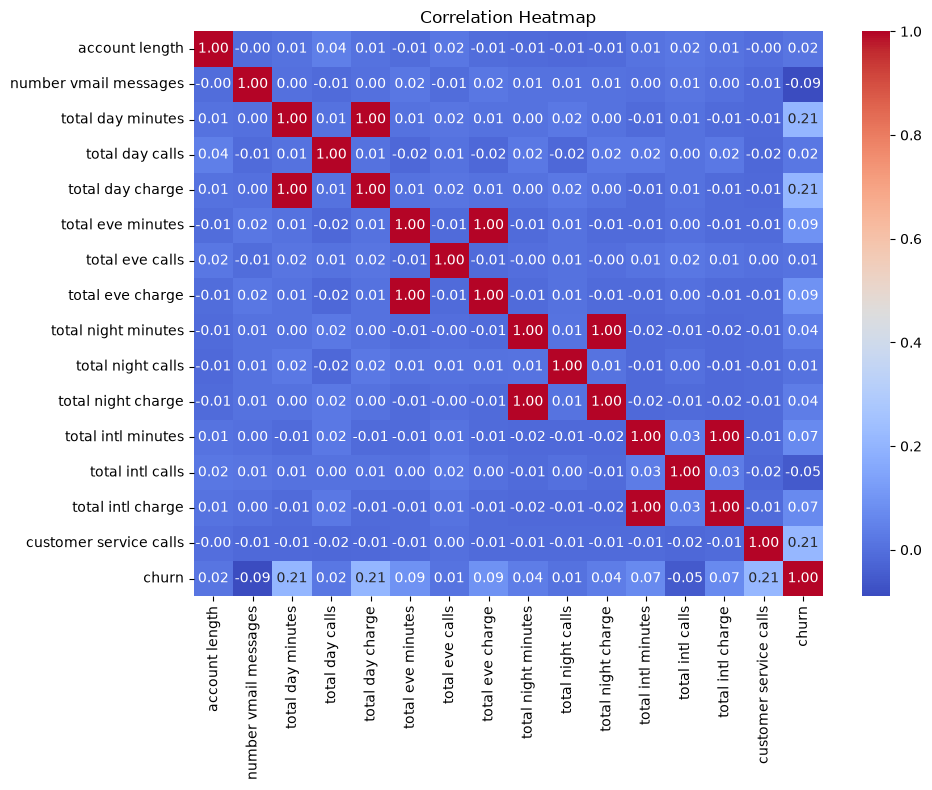

In [23]:
df_corr = df.copy()
df_corr['churn'] = df_corr['churn'].astype(int)
df_numeric = df_corr.select_dtypes(include='number')
df_numeric = df_numeric.drop(columns=['area code'])
corr = df_numeric.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [24]:
correlacion_churn = (corr['churn'].drop('churn').sort_values(ascending=False))
print(correlacion_churn.round(2))

customer service calls    0.21
total day minutes         0.21
total day charge          0.21
total eve minutes         0.09
total eve charge          0.09
total intl charge         0.07
total intl minutes        0.07
total night charge        0.04
total night minutes       0.04
total day calls           0.02
account length            0.02
total eve calls           0.01
total night calls         0.01
total intl calls         -0.05
number vmail messages    -0.09
Name: churn, dtype: float64


### 📊 Análisis de correlaciones

Hemos calculado la matriz de correlaciones de Pearson para estudiar las relaciones entre las variables numéricas y nuestra variable objetivo `churn`.

Las variables con mayor correlación positiva con el abandono son:

- `customer service calls`: 0,21.
- `total day minutes`: 0,21.
- `total day charge`: 0,21.

Por otro lado, `number vmail messages` presenta una correlación negativa de -0,09.

También hemos identificado correlaciones perfectas entre los minutos consumidos y sus respectivos costes, con valores de 1,00.

Esto indica que existe información redundante entre estas variables, ya que los costes se calculan directamente a partir de los minutos.

**Conclusión:** las correlaciones individuales con `churn` son relativamente débiles. No obstante, esto no significa que las variables carezcan de capacidad predictiva. Los modelos de clasificación pueden identificar relaciones no lineales y combinaciones de variables que no quedan reflejadas en la correlación de Pearson.

Cuando preparemos los datos, estudiaremos la eliminación de las variables de costes redundantes.

In [25]:
print("Variables Categoricas")
print(df.select_dtypes(include=['object', 'str']).columns.tolist())
print("Variables Numericas")
print(df.select_dtypes(include='number').columns.tolist())
print("Variable Objetivo")
print(df['churn'].dtype)

Variables Categoricas
['state', 'phone number', 'international plan', 'voice mail plan']
Variables Numericas
['account length', 'area code', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls']
Variable Objetivo
bool


In [26]:
df_ml = df.drop(columns=['area code',
                         'phone number',
                         'total day charge',
                         'total eve charge',
                         'total night charge',
                         'total intl charge'])


In [27]:
X = df_ml.drop(columns=['churn'])
y = df_ml['churn']

In [28]:
print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")
print(f"Variables Predictorias: {X.columns.tolist()}")
print(f"Distribución de y: {y.value_counts()}")
print(f"Proporción de y: {y.value_counts(normalize=True)}")

Dimensiones de X: (3333, 14)
Dimensiones de y: (3333,)
Variables Predictorias: ['state', 'account length', 'international plan', 'voice mail plan', 'number vmail messages', 'total day minutes', 'total day calls', 'total eve minutes', 'total eve calls', 'total night minutes', 'total night calls', 'total intl minutes', 'total intl calls', 'customer service calls']
Distribución de y: churn
False    2850
True      483
Name: count, dtype: int64
Proporción de y: churn
False    0.855086
True     0.144914
Name: proportion, dtype: float64


In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (2666, 14)
Dimensiones de X_test: (667, 14)


In [30]:
print(f"Distribucion de Entrenamiento: {y_train.value_counts(normalize=True) * 100}")
print(f"Distribucion de Prueba: {y_test.value_counts(normalize=True) * 100}")

Distribucion de Entrenamiento: churn
False    85.52138
True     14.47862
Name: proportion, dtype: float64
Distribucion de Prueba: churn
False    85.457271
True     14.542729
Name: proportion, dtype: float64


In [31]:
categorical_features = ['state',
                        'international plan',
                        'voice mail plan']
numerical_features = X_train.select_dtypes(include='number').columns.tolist()

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [33]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print(f"X_train original: {X_train.shape}")
print(f"X_test original: {X_test.shape}")
print(f"Shape of processed training data: {X_train_processed.shape}")
print(f"Shape of processed test data: {X_test_processed.shape}")

X_train original: (2666, 14)
X_test original: (667, 14)
Shape of processed training data: (2666, 66)
Shape of processed test data: (667, 66)


In [34]:
features_names = preprocessor.get_feature_names_out()
print(features_names)
print (f"Total number of features: {len(features_names)}")

['num__account length' 'num__number vmail messages'
 'num__total day minutes' 'num__total day calls' 'num__total eve minutes'
 'num__total eve calls' 'num__total night minutes'
 'num__total night calls' 'num__total intl minutes'
 'num__total intl calls' 'num__customer service calls' 'cat__state_AK'
 'cat__state_AL' 'cat__state_AR' 'cat__state_AZ' 'cat__state_CA'
 'cat__state_CO' 'cat__state_CT' 'cat__state_DC' 'cat__state_DE'
 'cat__state_FL' 'cat__state_GA' 'cat__state_HI' 'cat__state_IA'
 'cat__state_ID' 'cat__state_IL' 'cat__state_IN' 'cat__state_KS'
 'cat__state_KY' 'cat__state_LA' 'cat__state_MA' 'cat__state_MD'
 'cat__state_ME' 'cat__state_MI' 'cat__state_MN' 'cat__state_MO'
 'cat__state_MS' 'cat__state_MT' 'cat__state_NC' 'cat__state_ND'
 'cat__state_NE' 'cat__state_NH' 'cat__state_NJ' 'cat__state_NM'
 'cat__state_NV' 'cat__state_NY' 'cat__state_OH' 'cat__state_OK'
 'cat__state_OR' 'cat__state_PA' 'cat__state_RI' 'cat__state_SC'
 'cat__state_SD' 'cat__state_TN' 'cat__state_TX' '


# 📊 PROYECTO DE MACHINE LEARNING: CLASIFICACIÓN DE ABANDONO DE CLIENTES (CHURN)

## 🎯 1. Objetivo del proyecto

En este proyecto vamos a desarrollar un modelo de Machine Learning utilizando técnicas de clasificación.

Trabajaremos con un conjunto de datos de una compañía telefónica cuyo objetivo es identificar qué clientes tienen mayor probabilidad de abandonar la empresa.

Nuestra variable objetivo será `churn`:

- `False (0)`: el cliente permanece en la compañía.
- `True (1)`: el cliente abandona la compañía.

Se trata de un problema de **clasificación binaria**.

Nuestro propósito será estudiar el comportamiento de los clientes, identificar patrones relacionados con el abandono y construir modelos capaces de predecir esta situación.

---

## 📥 2. Carga y conocimiento del dataset

Nuestro conjunto de datos contiene:

- **3.333 registros (clientes).**
- **21 columnas (variables).**
- Variables numéricas, categóricas y una variable objetivo booleana.

### 🔎 Variables del dataset

**Variables categóricas:**

- `state`: estado del cliente.
- `phone number`: número telefónico.
- `international plan`: contratación del plan internacional.
- `voice mail plan`: contratación del servicio de buzón de voz.

**Variables numéricas:**

- `account length`
- `area code`
- `number vmail messages`
- `total day minutes`
- `total day calls`
- `total day charge`
- `total eve minutes`
- `total eve calls`
- `total eve charge`
- `total night minutes`
- `total night calls`
- `total night charge`
- `total intl minutes`
- `total intl calls`
- `total intl charge`
- `customer service calls`

**Variable objetivo:**

- `churn`

---

## 🧹 3. Auditoría y calidad de los datos

Antes de comenzar el análisis exploratorio, comprobamos la calidad del dataset.

### Resultados obtenidos:

- Valores nulos: **0**
- Filas duplicadas: **0**
- Registros: **3.333**
- Columnas: **21**

No encontramos valores nulos ni registros duplicados.

Por tanto, no fue necesario realizar imputaciones ni eliminar filas duplicadas.

También comprobamos los tipos de datos mediante `df.info()` y las estadísticas descriptivas mediante `df.describe()`.

---

## 📊 4. Distribución de la variable objetivo

Analizamos la distribución de `churn` para conocer cuántos clientes permanecen y cuántos abandonan la compañía.

### Resultados:

| Clasificación | Clientes | Porcentaje |
|---|---:|---:|
| No abandona (0) | 2.850 | 85,51 % |
| Sí abandona (1) | 483 | 14,49 % |
| **Total** | **3.333** | **100 %** |

### 🔍 Interpretación

Observamos que nuestro dataset presenta un desequilibrio entre las clases (*Class Imbalance*).

El 85,51 % de los clientes permanece en la compañía, mientras que solamente el 14,49 % la abandona.

Esto es importante porque un modelo podría conseguir una Accuracy elevada simplemente prediciendo que todos los clientes permanecen.

Por este motivo, posteriormente prestaremos especial atención a métricas como:

- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

No utilizaremos únicamente Accuracy para evaluar nuestros modelos.

---

## 📈 5. Análisis estadístico y comparación de promedios

Utilizamos `df.describe()` para estudiar las estadísticas descriptivas de las variables numéricas.

Analizamos:

- Media.
- Desviación estándar.
- Mínimo.
- Máximo.
- Cuartiles.

Posteriormente utilizamos `groupby('churn')` para comparar los promedios entre los clientes que permanecen y los que abandonan.

### Resultados destacados:

| Variable | No abandona | Abandona |
|---|---:|---:|
| Account length | 100,79 | 102,66 |
| Number vmail messages | 8,60 | 5,12 |
| Total day minutes | 175,18 | 206,91 |
| Total day calls | 100,28 | 101,34 |
| Total eve minutes | 199,04 | 212,41 |
| Total night minutes | 200,13 | 205,23 |
| Total intl minutes | 10,16 | 10,70 |
| Customer service calls | 1,45 | 2,23 |

### 🔍 Interpretación

Encontramos algunas diferencias interesantes:

1. Los clientes que abandonan consumen más minutos durante el día.
2. También presentan un mayor consumo de minutos por la tarde.
3. Realizan más llamadas al servicio de atención al cliente.
4. Tienen menos mensajes de voz que los clientes que permanecen.

Estas diferencias representan posibles patrones relacionados con el abandono.

Sin embargo, no podemos afirmar que estas variables provoquen directamente el abandono.

---

## 📊 6. Análisis de variables categóricas

Estudiamos las variables categóricas mediante `value_counts()`, `pd.crosstab()` y gráficos de barras.

El objetivo era descubrir si determinadas categorías presentaban mayores tasas de abandono.

### 🌍 International plan

| Plan internacional | No abandona | Abandona |
|---|---:|---:|
| No | 88,50 % | 11,50 % |
| Sí | 57,59 % | 42,41 % |

Los clientes que tienen contratado el plan internacional presentan una tasa de abandono considerablemente superior.

Esta variable muestra una asociación interesante con `churn`.

### 📞 Voice mail plan

| Plan de buzón de voz | No abandona | Abandona |
|---|---:|---:|
| No | 83,28 % | 16,72 % |
| Sí | 91,32 % | 8,68 % |

Los clientes que tienen contratado el servicio de buzón de voz presentan una tasa de abandono inferior.

### 📍 Area code

| Código de área | No abandona | Abandona |
|---|---:|---:|
| 408 | 85,44 % | 14,56 % |
| 415 | 85,74 % | 14,26 % |
| 510 | 85,12 % | 14,88 % |

Los tres códigos presentan tasas de abandono muy similares.

### 🌎 Análisis geográfico: State

También estudiamos los 51 estados para identificar diferencias geográficas.

Los estados con mayores tasas de abandono fueron:

| Estado | Clientes | Abandono |
|---|---:|---:|
| CA | 34 | 26,47 % |
| NJ | 68 | 26,47 % |
| TX | 72 | 25,00 % |
| MD | 70 | 24,29 % |
| SC | 60 | 23,33 % |

Los estados con menores tasas de abandono fueron:

| Estado | Clientes | Abandono |
|---|---:|---:|
| HI | 53 | 5,66 % |
| AK | 52 | 5,77 % |
| AZ | 64 | 6,25 % |
| VA | 77 | 6,49 % |
| IA | 44 | 6,82 % |

**Conclusión:** las variables `international plan`, `voice mail plan` y `state` presentan información interesante para nuestro problema de clasificación.

Debemos recordar que las tasas geográficas pueden variar por el número de observaciones de cada estado.

---

## 📉 7. Análisis de distribuciones mediante histogramas

Utilizamos histogramas con KDE para estudiar la distribución de las variables numéricas.

Observamos diferentes comportamientos:

### Distribuciones aproximadamente simétricas

Algunas variables presentan distribuciones relativamente equilibradas:

- `account length`
- `total day minutes`
- `total day calls`
- `total day charge`
- `total eve minutes`
- `total eve charge`
- `total night minutes`
- `total night charge`

### Variables con concentración de valores cero

- `number vmail messages`
- `total intl minutes`

Especialmente `number vmail messages`, donde encontramos una gran concentración de clientes con cero mensajes.

### Variables con asimetría positiva

- `total intl calls`
- `customer service calls`

En estas variables observamos una mayor concentración en valores pequeños y una cola hacia valores superiores.

**Conclusión:** las variables presentan diferentes distribuciones. No todas siguen una distribución normal y no es necesario que lo hagan para utilizar los algoritmos de clasificación que estudiaremos.

---

## 📦 8. Detección de valores atípicos (Outliers)

Utilizamos gráficos Boxplot y el método IQR (*Interquartile Range*) para identificar posibles observaciones atípicas.

La fórmula utilizada fue:

IQR = Q3 - Q1

Límite inferior = Q1 - 1.5 × IQR

Límite superior = Q3 + 1.5 × IQR

### Resultados destacados:

| Variable | Outliers | Porcentaje |
|---|---:|---:|
| customer service calls | 267 | 8,01 % |
| total intl calls | 78 | 2,34 % |
| total intl charge | 49 | 1,47 % |
| total intl minutes | 46 | 1,38 % |
| total night minutes | 30 | 0,90 % |
| total night charge | 30 | 0,90 % |

La variable `customer service calls` presenta el mayor número de posibles valores atípicos.

### 🔍 Decisión

No eliminamos ningún outlier.

El método IQR identifica observaciones alejadas de la distribución central, pero no demuestra que sean errores.

Algunos valores extremos pueden contener información importante para identificar clientes con mayor probabilidad de abandonar la compañía.

---

## 🔥 9. Matriz de correlaciones

Calculamos la matriz de correlaciones de Pearson para estudiar las relaciones entre las variables numéricas.

### Variables con mayor correlación respecto a Churn:

| Variable | Correlación |
|---|---:|
| customer service calls | +0,21 |
| total day minutes | +0,21 |
| total day charge | +0,21 |
| total eve minutes | +0,09 |
| total eve charge | +0,09 |
| total intl minutes | +0,07 |
| total intl charge | +0,07 |
| number vmail messages | -0,09 |
| total intl calls | -0,05 |

### 🔍 Interpretación

Las correlaciones individuales con `churn` son relativamente débiles.

Sin embargo, esto no significa que las variables carezcan de capacidad predictiva.

Los algoritmos de clasificación pueden identificar relaciones no lineales y combinaciones de variables que no quedan reflejadas en la correlación de Pearson.

### ⚠️ Multicolinealidad y variables redundantes

Encontramos correlaciones perfectas de 1,00 entre los minutos y sus respectivos costes:

- Total day minutes / Total day charge.
- Total eve minutes / Total eve charge.
- Total night minutes / Total night charge.
- Total intl minutes / Total intl charge.

Esto sucede porque los costes se calculan directamente a partir de los minutos consumidos.

Decidimos conservar las variables de minutos y eliminar las variables de costes para evitar información redundante en nuestro conjunto inicial de predictores.

---

## ⚙️ 10. Preparación de los datos para Machine Learning

Una vez terminado el análisis exploratorio, comenzamos a preparar nuestro dataset.

### 🗑️ Selección de variables

Decidimos eliminar las siguientes columnas:

- `phone number`: identificador individual del cliente.
- `area code`: código de área que consideramos poco relevante para nuestro objetivo.
- `total day charge`: redundante con los minutos diarios.
- `total eve charge`: redundante con los minutos de tarde.
- `total night charge`: redundante con los minutos nocturnos.
- `total intl charge`: redundante con los minutos internacionales.

Conservamos las demás variables predictoras.

### 🎯 Separación de X e y

Definimos:

- `X`: variables predictoras del cliente.
- `y`: variable objetivo `churn`.

Convertimos `churn` de booleano a entero:

- False = 0
- True = 1

### ✂️ División Train/Test

Utilizamos `train_test_split` con los siguientes parámetros:

- `test_size=0.20`
- `random_state=42`
- `stratify=y`

Separamos el 80 % de los datos para entrenamiento y el 20 % para pruebas.

Utilizamos `stratify=y` para conservar aproximadamente la misma proporción de clases en ambos conjuntos.

---

## 🔠 11. Codificación de variables categóricas: One-Hot Encoding

Para que los algoritmos de Machine Learning puedan trabajar con las variables categóricas, utilizamos One-Hot Encoding.

Aplicamos este procedimiento a:

- `state`
- `international plan`
- `voice mail plan`

Utilizamos:

`OneHotEncoder(handle_unknown='ignore')`

Esto transforma las categorías en columnas binarias.

Por ejemplo:

- international plan_no
- international plan_yes
- voice mail plan_no
- voice mail plan_yes

También transformamos los 51 estados en sus correspondientes columnas binarias.

---

## ⚖️ 12. Estandarización de variables numéricas

Utilizamos `StandardScaler` para estandarizar las variables numéricas.

La transformación se basa en:

Z = (X - media) / desviación estándar

De esta manera, las variables numéricas quedan expresadas en una escala comparable.

Esto resulta especialmente útil para algoritmos como Regresión Logística.

---

## 🔧 13. ColumnTransformer

Utilizamos `ColumnTransformer` para combinar los dos procesos de transformación:

**Variables numéricas:**
- StandardScaler.

**Variables categóricas:**
- OneHotEncoder.

De esta manera construimos un preprocesador que aplica automáticamente la transformación correspondiente a cada grupo de variables.

---

## 🔄 14. Transformación de los datos

Aplicamos el preprocesador utilizando:

- `fit_transform(X_train)`: aprende los parámetros y transforma los datos de entrenamiento.
- `transform(X_test)`: transforma los datos de prueba utilizando los parámetros aprendidos durante el entrenamiento.

Esto evita el Data Leakage, ya que el conjunto de prueba no interviene en el aprendizaje del preprocesador.

### Resultados obtenidos

Después de aplicar One-Hot Encoding y StandardScaler obtuvimos:

**66 variables predictoras transformadas.**

Distribuidas de la siguiente manera:

| Tipo de variable | Número de columnas |
|---|---:|
| Variables numéricas estandarizadas | 11 |
| Variables categóricas de State | 51 |
| International plan | 2 |
| Voice mail plan | 2 |
| **Total** | **66** |

El resultado final es una matriz de datos numéricos preparada para utilizar nuestros algoritmos de clasificación.

---

## 🚀 15. Próxima etapa: entrenamiento de modelos de clasificación

Hemos terminado el análisis exploratorio y la preparación inicial de los datos.

Ahora comenzaremos a entrenar diferentes algoritmos de clasificación.

### 🤖 Modelos que estudiaremos

1. Logistic Regression.
2. Decision Tree Classifier.
3. Random Forest Classifier.

### 📊 Métricas de evaluación

Para comparar los modelos utilizaremos:

- Accuracy: porcentaje total de predicciones correctas.
- Precision: proporción de predicciones positivas que son correctas.
- Recall: proporción de abandonos reales que conseguimos detectar.
- F1-score: equilibrio entre Precision y Recall.
- Confusion Matrix: matriz de confusión.
- ROC-AUC: capacidad del modelo para distinguir entre ambas clases.

También estudiaremos:

- Cross-Validation.
- GridSearchCV.
- Optimización de hiperparámetros.
- Class Imbalance.
- Class Weight.
- Posible utilización de SMOTE.

### 🏆 Objetivo final

Comparar los diferentes modelos y seleccionar el que mejor identifique a los clientes con riesgo de abandonar la compañía.

No elegiremos necesariamente el modelo con mayor Accuracy, sino aquel que ofrezca el mejor equilibrio de rendimiento y capacidad para detectar los abandonos.

---

## 🧠 CONCLUSIÓN GENERAL DEL ANÁLISIS EXPLORATORIO

Durante esta primera fase hemos aprendido a explorar, interpretar y preparar un conjunto de datos destinado a un problema de clasificación.

Hemos identificado diferencias en el comportamiento de los clientes, estudiado las relaciones entre variables, detectado posibles valores atípicos y preparado los datos mediante codificación y estandarización.

También hemos comprobado que nuestro conjunto de datos presenta un desequilibrio entre las clases, lo que será especialmente importante durante la evaluación de los modelos.

**El dataset está preparado para comenzar nuestra etapa de clasificación.**

¡Ahora comienza el entrenamiento de nuestros primeros modelos de Machine Learning! 🚀🤖


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', LogisticRegression(max_iter=100, 
                                      random_state=42))])

In [36]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['state','account length','international plan',...,'total intl minutes', 'total intl calls','customer service calls']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [37]:
print("Modelo Recientemente Entrenado")
print(f"Numero de Registros de Entrenamiento: {len(X_train)}")
print(f"Numero de Variables Predictoras: {len(logistic_model.named_steps['classifier'].coef_[0])}")
print("Intercepto")
print(logistic_model.named_steps['classifier'].intercept_)

Modelo Recientemente Entrenado
Numero de Registros de Entrenamiento: 2666
Numero de Variables Predictoras: 66
Intercepto
[-1.96630648]


In [38]:
y_pred = logistic_model.predict(X_test)
print(y_pred[:20])

[False False False False False False False False False False False False
 False  True False False False False False False]


In [39]:
y_proba = logistic_model.predict_proba(X_test)
print(y_proba[:20])

[[0.82289969 0.17710031]
 [0.87391041 0.12608959]
 [0.88245812 0.11754188]
 [0.86890821 0.13109179]
 [0.64947839 0.35052161]
 [0.94227017 0.05772983]
 [0.72136167 0.27863833]
 [0.87993751 0.12006249]
 [0.96600289 0.03399711]
 [0.89615179 0.10384821]
 [0.98892494 0.01107506]
 [0.9687805  0.0312195 ]
 [0.82108802 0.17891198]
 [0.26589858 0.73410142]
 [0.97391654 0.02608346]
 [0.79986955 0.20013045]
 [0.9862802  0.0137198 ]
 [0.97688784 0.02311216]
 [0.99366218 0.00633782]
 [0.87644736 0.12355264]]


In [40]:
print("predicciones:" , y_pred.shape)
print("probabilidades:" , y_proba.shape)
print("Valores Reales:" , y_test.shape)

predicciones: (667,)
probabilidades: (667, 2)
Valores Reales: (667,)


In [41]:
resultados = pd.DataFrame({
    'Real ' : y_test.astype('int').values,
    'Predicción ' : y_pred.astype('int'),
    'Probabilidad de Abandono ' : y_proba[:, 1]
})
resultados.head(15)

,Real,Predicción,Probabilidad de Abandono
0,1,0,0.177100
1,0,0,0.126090
2,0,0,0.117542
3,0,0,0.131092
4,0,0,0.350522
5,0,0,0.057730
6,0,0,0.278638
7,0,0,0.120062
8,0,0,0.033997
9,0,0,0.103848


In [42]:
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

Accuracy: 0.8620689655172413
Confusion Matrix:
 [[550  20]
 [ 72  25]]
Classification Report:
               precision    recall  f1-score   support

       False       0.88      0.96      0.92       570
        True       0.56      0.26      0.35        97

    accuracy                           0.86       667
   macro avg       0.72      0.61      0.64       667
weighted avg       0.84      0.86      0.84       667



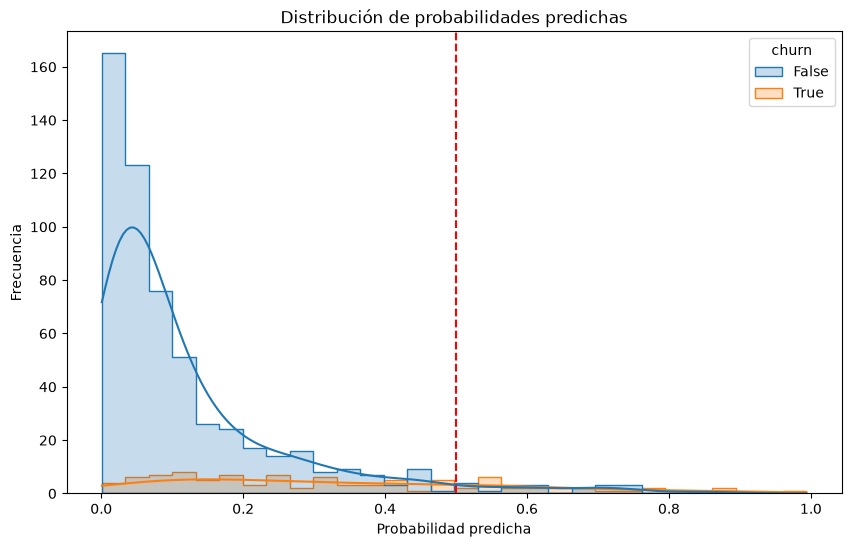

In [43]:
plt.figure(figsize=(10, 6))
sns.histplot(
    x = y_proba[:, 1],
    hue = y_test,
    bins = 30,
    kde = True,
    element = "step"
)
plt.axvline(x=0.5, color='red', linestyle='--')
plt.title("Distribución de probabilidades predichas")
plt.xlabel("Probabilidad predicha")
plt.ylabel("Frecuencia")
plt.legend
plt.show()

In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score
umbrales= [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
resultados = []
for umbral in umbrales:
    y_pred = (y_proba[:, 1] >= umbral).astype(int)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    resultados.append({
        "umbral": umbral,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

df_umbrales = pd.DataFrame(resultados)
df_umbrales

,umbral,precision,recall,f1
0,0.20,0.363636,0.618557,0.458015
1,0.25,0.407407,0.567010,0.474138
2,0.30,0.452830,0.494845,0.472906
3,0.35,0.476190,0.412371,0.441989
4,0.40,0.514286,0.371134,0.431138
5,0.50,0.555556,0.257732,0.352113


In [45]:
umbrel = 0.25
y_pred_25 = (y_proba[:, 1] >= umbrel).astype(int)
matriz = confusion_matrix(y_test, y_pred_25)
reporte_clasificacion = classification_report(y_test, y_pred_25)
print("Matriz de confusión:\n", matriz)
print("\nReporte de clasificación:\n", reporte_clasificacion)

Matriz de confusión:
 [[490  80]
 [ 42  55]]

Reporte de clasificación:
               precision    recall  f1-score   support

       False       0.92      0.86      0.89       570
        True       0.41      0.57      0.47        97

    accuracy                           0.82       667
   macro avg       0.66      0.71      0.68       667
weighted avg       0.85      0.82      0.83       667



### 📊 Evaluación de la regresión logística y ajuste del umbral

Inicialmente, entrenamos una regresión logística utilizando el umbral predeterminado de 0,50. Obtuvimos un Accuracy del 86,21 %, pero el Recall de la clase de abandono fue solamente del 25,77 %.

Esto significa que el modelo identificaba correctamente una proporción muy baja de los clientes que realmente abandonaban.

Posteriormente, probamos diferentes umbrales de clasificación (0,20, 0,25, 0,30, 0,35, 0,40 y 0,50).

El mejor F1-score se obtuvo con el umbral de 0,25, alcanzando un valor de 0,474.

**Comparación de resultados:**

- Umbral 0,50: Recall = 25,77 %, F1-score = 0,352.
- Umbral 0,25: Recall = 56,70 %, F1-score = 0,474.

Con el umbral de 0,25 conseguimos identificar 55 de los 97 clientes que abandonaron, frente a solamente 25 con el umbral predeterminado.

Sin embargo, también aumentaron los falsos positivos, pasando de 20 a 80, y el Accuracy descendió al 82,31 %.

**Conclusión:** el ajuste del umbral permitió mejorar la capacidad de detección de clientes que abandonan. Para este ejercicio seleccionamos provisionalmente 0,25 porque obtuvo el mayor F1-score entre los umbrales evaluados. La elección definitiva dependerá del equilibrio entre los costes de los falsos positivos y los falsos negativos.

In [46]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_proba[:, 1])
roc_auc = roc_auc_score(y_test, y_proba[:, 1])
print("roc_auc:", roc_auc)

roc_auc: 0.8096039066739013


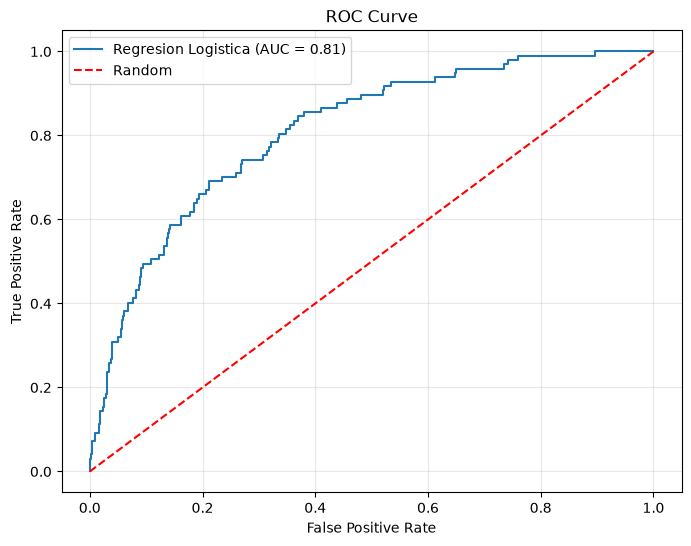

In [47]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr,
         label=f'Regresion Logistica (AUC = {roc_auc:.2f})')
plt.plot(
    [0, 1], [0, 1], color='red', linestyle='--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 📈 Evaluación de la curva ROC y ROC-AUC

Una vez entrenada nuestra regresión logística, evaluamos su capacidad de discriminación mediante la curva ROC (*Receiver Operating Characteristic*) y el área bajo la curva (AUC).

Obtuvimos un resultado de:

**ROC-AUC = 0,81**

Este valor indica que nuestro modelo presenta una buena capacidad para distinguir entre clientes que permanecen y clientes que abandonan.

La curva ROC representa la relación entre:

- TPR (True Positive Rate): proporción de abandonos correctamente detectados.
- FPR (False Positive Rate): proporción de clientes que permanecen clasificados incorrectamente como abandonos.

La curva de nuestro modelo se encuentra claramente por encima de la diagonal correspondiente al clasificador aleatorio, cuyo AUC es 0,50.

**Conclusión:**

Aunque inicialmente obtuvimos un Recall bajo utilizando el umbral predeterminado de 0,50, el ROC-AUC de 0,81 demuestra que el modelo dispone de una capacidad razonable para distinguir entre ambas clases.

Posteriormente, ajustando el umbral a 0,25, conseguimos mejorar la detección de clientes que abandonan, aumentando el Recall del 25,77 % al 56,70 %.

Esto demuestra la importancia de evaluar los modelos de clasificación mediante diferentes métricas y no depender exclusivamente del Accuracy.

In [48]:
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy',
           'precision': 'precision',
           'recall': 'recall',
           'f1': 'f1',
           'roc_auc': 'roc_auc'}
resultados_cv = cross_validate(
    logistic_model,
    X_train, y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
    )

In [49]:
df_skf = pd.DataFrame({
    'accuracy': resultados_cv['test_accuracy'],
    'precision': resultados_cv['test_precision'],
    'recall': resultados_cv['test_recall'],
    'f1': resultados_cv['test_f1'],
    'roc_auc': resultados_cv['test_roc_auc']
})
df_skf.index = [f'Fold {i}' for i in range(1, 6)]
df_skf.round(3)

,accuracy,precision,recall,f1,roc_auc
Fold 1,0.856,0.515,0.218,0.306,0.792
Fold 2,0.859,0.524,0.286,0.370,0.824
Fold 3,0.859,0.542,0.169,0.257,0.830
Fold 4,0.857,0.517,0.195,0.283,0.808
Fold 5,0.872,0.636,0.273,0.382,0.805


In [50]:
print("Promedio de las Metricas")
print(df_skf.mean().round(3))
print("\nDesviación estándar de las métricas")
print(df_skf.std().round(3))

Promedio de las Metricas
accuracy     0.861
precision    0.547
recall       0.228
f1           0.320
roc_auc      0.812
dtype: float64

Desviación estándar de las métricas
accuracy     0.007
precision    0.051
recall       0.050
f1           0.054
roc_auc      0.015
dtype: float64


### 🔄 Validación cruzada (Cross-Validation)

Para comprobar la estabilidad de nuestra regresión logística utilizamos `StratifiedKFold` con cinco particiones.

La validación cruzada entrenó y evaluó el modelo cinco veces, manteniendo aproximadamente la proporción original de las clases en cada partición.

**Resultados medios:**

- Accuracy: 0,861.
- Precision: 0,547.
- Recall: 0,228.
- F1-score: 0,320.
- ROC-AUC: 0,812.

**Desviación estándar:**

- Accuracy: 0,007.
- Precision: 0,051.
- Recall: 0,050.
- F1-score: 0,054.
- ROC-AUC: 0,015.

**Conclusión:**

Los resultados muestran que la regresión logística mantiene un rendimiento bastante estable en las diferentes particiones, especialmente en Accuracy y ROC-AUC.

El ROC-AUC medio de 0,812 es prácticamente igual al obtenido anteriormente en el conjunto de prueba (0,81), lo que indica una capacidad de discriminación consistente.

Sin embargo, el Recall medio de 0,228 evidencia que el modelo todavía tiene dificultades para identificar a los clientes que abandonan utilizando el umbral predeterminado de 0,50.

Por tanto, será necesario estudiar estrategias para mejorar la detección de la clase minoritaria.

In [51]:
logistic_balanced = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000, class_weight='balanced', random_state=42))
    ]
)
logistic_balanced.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['state','account length','international plan',...,'total intl minutes', 'total intl calls','customer service calls']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [52]:
y_pred_balanced = logistic_balanced.predict(X_test)
y_proba_balanced = logistic_balanced.predict_proba(X_test)
print("Primeras predicciones:")
print(y_pred_balanced[:10])
print("Primeras probabilidades:")
print(y_proba_balanced[:10])
print("Dimensiones de las predicciones:")
print(y_pred_balanced.shape)
print("Dimensiones de las probabilidades:")
print(y_proba_balanced.shape)

Primeras predicciones:
[ True False  True False  True False  True False False False]
Primeras probabilidades:
[[0.37168955 0.62831045]
 [0.51619739 0.48380261]
 [0.47259664 0.52740336]
 [0.59972207 0.40027793]
 [0.19581977 0.80418023]
 [0.68396539 0.31603461]
 [0.35995716 0.64004284]
 [0.6167771  0.3832229 ]
 [0.81901839 0.18098161]
 [0.6292641  0.3707359 ]]
Dimensiones de las predicciones:
(667,)
Dimensiones de las probabilidades:
(667, 2)


In [53]:
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_balanced))
print("Reporte de clasificación:", classification_report(y_test, y_pred_balanced))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba_balanced[:, 1]))

Accuracy: 0.7481259370314842
Matriz de confusión:
[[430 140]
 [ 28  69]]
Reporte de clasificación:               precision    recall  f1-score   support

       False       0.94      0.75      0.84       570
        True       0.33      0.71      0.45        97

    accuracy                           0.75       667
   macro avg       0.63      0.73      0.64       667
weighted avg       0.85      0.75      0.78       667

ROC AUC Score: 0.8034002532103455


In [54]:
umbral_balanced = [0.30, 0.35, 0.40, 0.45, 0.50]
resultados_balanced = []
for umbral in umbral_balanced:
    y_pred_umbral = (y_proba_balanced[:, 1] >= umbral).astype(int)
    resultados_balanced.append({
        'umbral': umbral,
        'precision': precision_score(y_test, y_pred_umbral),
        'recall': recall_score(y_test, y_pred_umbral),
        'f1': f1_score(y_test, y_pred_umbral)
    })
df_umbral_balanced = pd.DataFrame(resultados_balanced)
df_umbral_balanced.round(2)

,umbral,precision,recall,f1
0,0.30,0.24,0.88,0.38
1,0.35,0.26,0.85,0.40
2,0.40,0.28,0.78,0.41
3,0.45,0.31,0.75,0.44
4,0.50,0.33,0.71,0.45


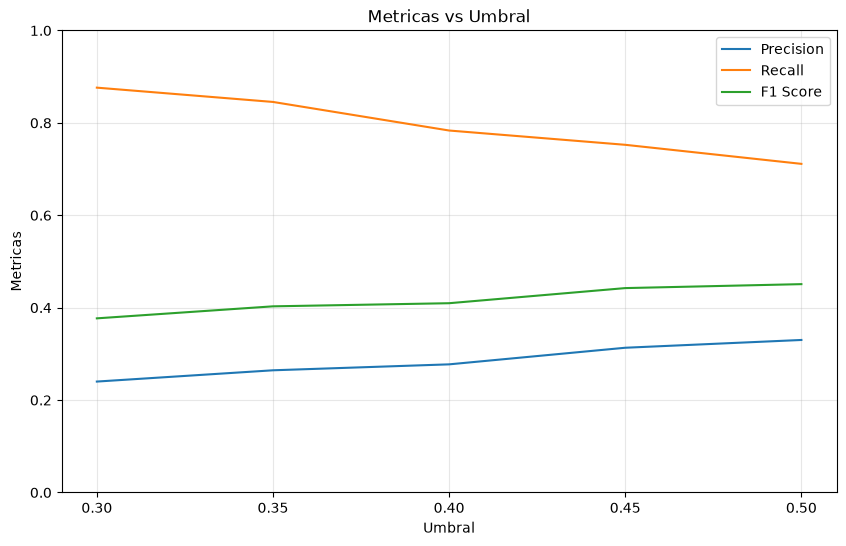

In [55]:
plt.figure(figsize=(10, 6))
plt.plot(df_umbral_balanced['umbral'], df_umbral_balanced['precision'], label='Precision')
plt.plot(df_umbral_balanced['umbral'], df_umbral_balanced['recall'], label='Recall')
plt.plot(df_umbral_balanced['umbral'], df_umbral_balanced['f1'], label='F1 Score')
plt.xlabel('Umbral')
plt.ylabel('Metricas')
plt.title('Metricas vs Umbral')
plt.xticks(df_umbral_balanced['umbral'])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# 📊 Conclusión final: Regresión Logística

## 1. Introducción

Durante esta fase del proyecto Telecom Customer Churn hemos desarrollado un modelo de clasificación mediante Regresión Logística, cuyo objetivo es predecir si un cliente permanecerá en la compañía o abandonará el servicio (*Churn*).

Nuestro objetivo no ha sido únicamente conseguir un Accuracy elevado, sino desarrollar un modelo capaz de identificar correctamente a los clientes que tienen mayor probabilidad de abandonar.

## 2. Preparación de los datos

Antes de entrenar el modelo realizamos un proceso de preparación y transformación de los datos:

- Eliminamos `phone number` por tratarse de un identificador sin utilidad predictiva directa.
- Eliminamos `area code` porque decidimos que no aportaba información relevante para nuestro análisis.
- Eliminamos las columnas de costes (`total day charge`, `total eve charge`, `total night charge` y `total intl charge`) debido a su redundancia con las variables de minutos correspondientes.
- Conservamos las variables categóricas relevantes: `state`, `international plan` y `voice mail plan`.
- Separamos las variables predictoras (X) de la variable objetivo (y).
- Dividimos los datos en entrenamiento (80 %) y prueba (20 %), utilizando `stratify=y` para mantener la proporción de las clases.

Posteriormente, construimos un preprocesador mediante `ColumnTransformer`:

- `StandardScaler`: estandarización de las variables numéricas.
- `OneHotEncoder`: transformación de las variables categóricas en variables binarias.

Finalmente, integramos el preprocesamiento y la regresión logística mediante `Pipeline`, evitando fugas de información durante el entrenamiento y la validación.

## 3. Entrenamiento y evaluación del modelo original

Entrenamos nuestra primera regresión logística utilizando los parámetros iniciales:

- `max_iter=1000`
- `random_state=42`

Obtuvimos los siguientes resultados con el umbral predeterminado de 0,50:

| Métrica | Resultado |
|---|---:|
| Accuracy | 86,21 % |
| Precision (Churn) | 55,56 % |
| Recall (Churn) | 25,77 % |
| F1-score (Churn) | 35,21 % |
| ROC-AUC | 0,81 |

Aunque el Accuracy fue elevado, observamos que el modelo tenía dificultades para detectar a los clientes que realmente abandonaban.

De los 97 clientes que abandonaron en el conjunto de prueba, solamente identificó correctamente a 25.

Esto nos permitió comprender que, en un problema de clasificación con clases desequilibradas, el Accuracy no es suficiente para evaluar el rendimiento del modelo.

## 4. Ajuste del umbral de clasificación

Posteriormente, estudiamos cómo influye el umbral de clasificación en las predicciones.

Probamos los valores 0,20, 0,25, 0,30, 0,35, 0,40 y 0,50.

El mejor F1-score de los umbrales evaluados se obtuvo con 0,25:

| Métrica | Umbral 0,50 | Umbral 0,25 |
|---|---:|---:|
| Precision | 55,56 % | 40,74 % |
| Recall | 25,77 % | 56,70 % |
| F1-score | 35,21 % | 47,41 % |
| Accuracy | 86,21 % | 81,71 % |

Con el umbral de 0,25 conseguimos detectar 55 de los 97 clientes que abandonaron, frente a los 25 detectados inicialmente.

Sin embargo, aumentaron los falsos positivos.

**Aprendizaje:** reducir el umbral permite detectar más clientes que abandonan, aunque puede provocar un incremento de las falsas alarmas.

## 5. Evaluación mediante la curva ROC y AUC

Utilizamos la curva ROC para estudiar la capacidad del modelo para distinguir entre clientes que permanecen y clientes que abandonan, considerando diferentes umbrales.

Obtuvimos:

**ROC-AUC = 0,81**

Este resultado indica que nuestra regresión logística presenta una buena capacidad de discriminación.

También comprendimos que ROC-AUC y Recall miden aspectos diferentes:

- Recall evalúa la detección de abandonos con un umbral determinado.
- ROC-AUC evalúa la capacidad de discriminación considerando todos los umbrales.

Por tanto, un modelo puede presentar un AUC razonablemente bueno y, al mismo tiempo, tener un Recall bajo con el umbral predeterminado.

## 6. Validación cruzada (Cross-Validation)

Para comprobar la estabilidad del modelo utilizamos `StratifiedKFold` con cinco particiones.

Aplicamos `cross_validate()` para obtener diferentes métricas en cada iteración.

**Resultados medios:**

| Métrica | Promedio |
|---|---:|
| Accuracy | 0,861 |
| Precision | 0,547 |
| Recall | 0,228 |
| F1-score | 0,320 |
| ROC-AUC | 0,812 |

**Desviación estándar:**

| Métrica | Desviación |
|---|---:|
| Accuracy | 0,007 |
| Precision | 0,051 |
| Recall | 0,050 |
| F1-score | 0,054 |
| ROC-AUC | 0,015 |

Los resultados mostraron que el modelo mantiene un comportamiento bastante estable, especialmente en Accuracy y ROC-AUC.

Sin embargo, el Recall medio continuó siendo bajo utilizando el umbral predeterminado de 0,50.

## 7. Tratamiento del desequilibrio de clases: class_weight='balanced'

Como nuestro dataset contiene aproximadamente un 85,51 % de clientes que permanecen y un 14,49 % que abandonan, probamos una segunda regresión logística utilizando:

`class_weight='balanced'`

Este parámetro asigna automáticamente un peso mayor a la clase minoritaria durante el entrenamiento.

Obtuvimos los siguientes resultados:

| Métrica | Modelo original | Modelo balanced |
|---|---:|---:|
| Accuracy | 86,21 % | 74,81 % |
| Precision (Churn) | 55,56 % | 33,01 % |
| Recall (Churn) | 25,77 % | 71,13 % |
| F1-score (Churn) | 35,21 % | 45,10 % |
| ROC-AUC | 0,810 | 0,803 |

La mejora más importante fue el Recall, que pasó del 25,77 % al 71,13 %.

En la matriz de confusión observamos que los falsos negativos disminuyeron de 72 a 28.

Sin embargo, los falsos positivos aumentaron de 20 a 140.

**Aprendizaje:** `class_weight='balanced'` permite dar mayor importancia a la clase minoritaria, mejorando su detección, aunque puede reducir otras métricas como Accuracy y Precision.

## 8. Ajuste del umbral en el modelo balanceado

Finalmente, probamos diferentes umbrales en la regresión logística balanceada:

| Umbral | Precision | Recall | F1-score |
|---|---:|---:|---:|
| 0,30 | 0,24 | 0,88 | 0,38 |
| 0,35 | 0,26 | 0,85 | 0,40 |
| 0,40 | 0,28 | 0,78 | 0,41 |
| 0,45 | 0,31 | 0,75 | 0,44 |
| 0,50 | 0,33 | 0,71 | 0,45 |

El umbral 0,50 obtuvo el mayor F1-score entre los valores probados, mientras que el umbral 0,30 consiguió el mayor Recall.

Esto confirmó que el umbral permite controlar el equilibrio entre la detección de abandonos y los falsos positivos.

## 9. Conclusión general

La regresión logística nos ha permitido comprender los fundamentos de un problema de clasificación binaria y aplicar diferentes técnicas de evaluación y mejora de modelos.

Hemos aprendido que un Accuracy elevado no garantiza que el modelo detecte correctamente la clase minoritaria y que es necesario analizar otras métricas, especialmente Precision, Recall y F1-score.

También hemos comprobado que podemos modificar el comportamiento del clasificador mediante el ajuste del umbral y el uso de `class_weight='balanced'`.

En nuestros experimentos, el modelo original con umbral 0,25 obtuvo el mejor F1-score (0,474) entre las configuraciones comparadas, mientras que el modelo balanceado con umbral 0,50 consiguió el mayor Recall (0,711).

Por tanto, no existe una única configuración ideal: la elección depende del objetivo del problema y del coste asociado a cada tipo de error.

**Conclusión final:** la regresión logística constituye nuestro primer modelo de referencia (*baseline*). Hemos aprendido a entrenarlo, evaluarlo, interpretar sus resultados y aplicar estrategias para mejorar la detección de la clase minoritaria.

Ahora utilizaremos los conocimientos adquiridos para estudiar otros algoritmos de clasificación y comparar sus resultados, buscando un modelo que consiga un mejor equilibrio entre capacidad predictiva, detección de abandonos y estabilidad.

🚀 **Finalizamos la etapa de Regresión Logística y continuamos con Decision Tree Classifier.**